
# Exercise 2: Classification using Transformer

---

## Introduction

In this exercise, you will learn how to use Long Short-Term Memory (LSTM) and Transformer models for text classification on the IMDB dataset, which consists of movie reviews labeled as positive or negative. You will train and evaluate each model, calculating their precision to determine which model performs best for this particular task.

## Tasks

### Task 1: Prepare the Dataset
1. Load the IMDB dataset and the stemming dictionary into your environment.
2. Execute the provided preprocessing code:
   - Convert all text to lowercase.
   - Remove special characters and stop words.
   - Split the data into training, validation, and test sets.

### Task 2: Explore Dataset Statistics
1. Analyze the dataset to understand the distribution of reviews (e.g., number of reviews, lengths of reviews, number of unique words, etc.).
2. Complete the code to:
   - Pad the sequences so they all have the same length.
   - Create input-output pairs for training and testing.

### Task 3: Train the Models
1. Implement and train two models:
   - **LSTM-based model**: Use a Long Short-Term Memory (LSTM) network to capture sequential dependencies in the text.
   - **Transformer-based model**: Use a Transformer model to leverage attention mechanisms for text classification.
   
2. Evaluate the models using precision, recall, and F1-score. Compare the results to determine which model performs best.

### Task 4: Hyperparameter Tuning
Tune the hyperparameters for each model (e.g., number of layers, number of units, learning rate, batch size) to optimize their performance.

### Task 5: Compare and Conclude
After training and evaluating the models, compare their precision scores and conclude which model is better suited for the task.



In [1]:
!pip install nltk
!pip install keras-nlp
import nltk
nltk.download('stopwords')

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   -------------------------------

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True


imdb_df Dataset Statistics:
Number of instances per class:
label
1    25000
0    25000
Name: count, dtype: int64
Average number of words per review: 89.69
Vocabulary size: 83539



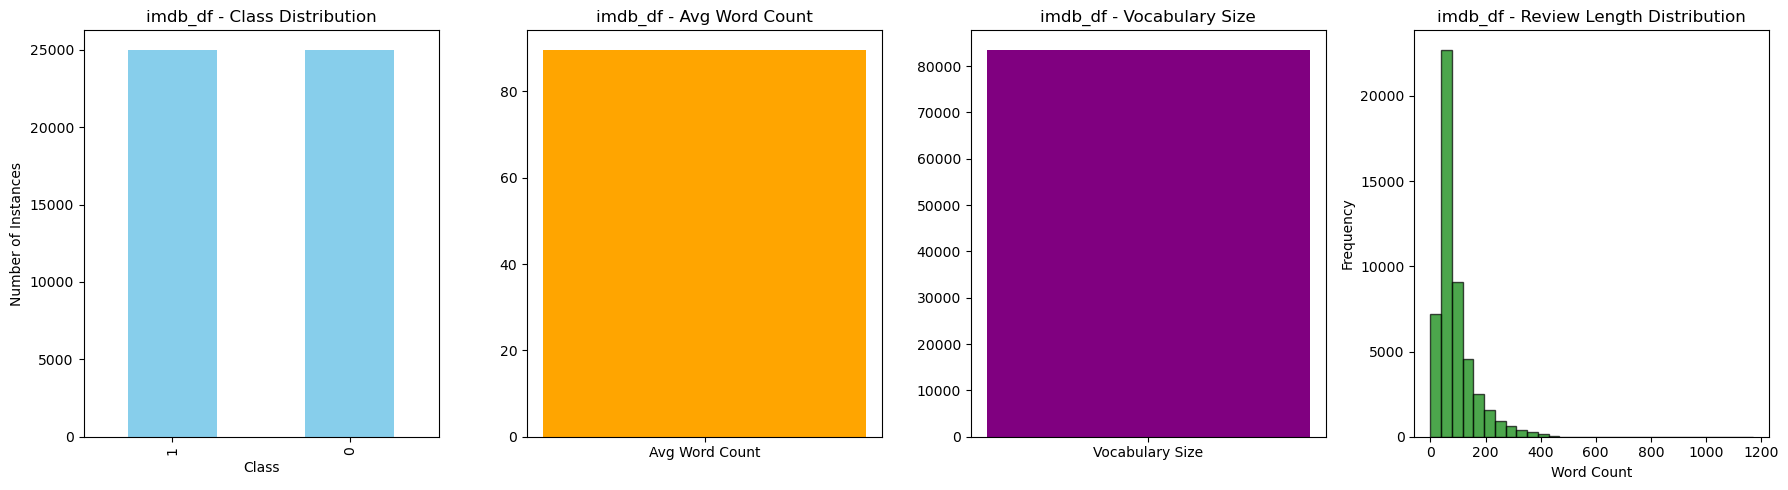

In [2]:
import numpy as np
import pandas as pd
import re
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, LSTM, GRU, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from collections import defaultdict
import matplotlib.pyplot as plt
import json

# Create a dictionary with default value False for stopwords
stop_words_dict = defaultdict(bool)
for w in set(stopwords.words('english')):
    stop_words_dict[w.lower()] = True


# 1. Preprocessing Function
def preprocess_text(text, stem=False, stemmer=None, stemming_dict=None):
    """
    Goal: Clean and preprocess text data by removing HTML tags, stopwords,
          and optionally applying stemming.

    Input:
    - text (str): The input text to be cleaned.
    - stem (bool): If True, applies stemming. Default is False.
    - stemmer (object): An instance of a stemming algorithm (e.g., PorterStemmer). Required if `stem=True`.
    - stemming_dict (dict): A dictionary containing words from imdb dataset along with their stems. Optional.

    Output:
    - str: The preprocessed text after cleaning and optional stemming.

    Example:
    Input: "The quick brown fox jumped over the lazy dog."
    Output: "quick brown fox jumped lazy dog"
    """
    # Remove HTML tags using regex
    no_tags = re.sub('<[^<]+?>', '', text)

    # Convert to lowercase
    lowercase_sent = no_tags.lower()

    # Keep only alphabetic words and remove stopwords
    tokens = [word for word in lowercase_sent.split() if word.isalpha() and word not in stop_words_dict]

    if stem:
        # Apply stemming if specified
        stemmed_tokens = []
        for token in tokens:
            if token in stemming_dict:
                stemmed_tokens.append(stemming_dict[token])
            else:
                stemmed_tokens.append(stemmer.stem(token))
        tokens = stemmed_tokens

    # Return preprocessed text as a space-separated string
    return ' '.join(tokens)

def load_stemming_dict(file_path):
    """
    Goal: Load a custom stemming dictionary from a JSON file.

    Input:
    - file_path (str): Path to the JSON file containing the stemming dictionary.

    Output:
    - dict: The loaded stemming dictionary.

    Example:
    Input: "stemming_dict.json"
    Output: {'running': 'run', 'happier': 'happy', ...}
    """
    with open(file_path, 'r') as file:
        stemming_dict = json.load(file)
    print(f"Stemming dictionary loaded from {file_path}")
    return stemming_dict



# 2. Dataset Loading and Preprocessing
def load_and_preprocess_dataset(dataset_path, preprocess=False, stem=False, stemming_dict_file="defaultdict_stemming.json"):
    """
    Goal: Load and preprocess the dataset from a CSV file, applying optional text preprocessing steps.

    Input:
    - dataset_path (str): Path to the CSV file containing the dataset.
    - preprocess (bool): If True, preprocesses the text data.
    - stem (bool): If True, applies stemming during preprocessing.
    - stemming_dict_file (str): Path to the stemming dictionary file (used when `stem=True`).

    Output:
    - pandas.DataFrame: A DataFrame containing the preprocessed dataset.

    Example:
    Input: "IMDB_Dataset.csv", preprocess=True, stem=True
    Output: A DataFrame with 'text' and 'label' columns, with preprocessed text.
    """
    if 'IMDB_Dataset.csv' in dataset_path:
        # Load the IMDB dataset and rename columns
        dataset = pd.read_csv(dataset_path, usecols=['review', 'sentiment'])
        dataset = dataset.rename(columns={'review': 'text', 'sentiment': 'label'})
        dataset['label'] = dataset['label'].apply(lambda x: 1 if x == 'positive' else 0)
    else:
        raise ValueError("Invalid dataset path. Please provide the correct path.")

    if preprocess:  # Preprocess text data
        if stem:
            stemming_dict = load_stemming_dict(stemming_dict_file)
            stemmer = PorterStemmer()
        else:
            stemming_dict = None
            stemmer = None
        dataset['text'] = dataset['text'].apply(lambda x: preprocess_text(x, stem, stemmer=stemmer, stemming_dict=stemming_dict))

    return dataset


# 3. Split Data into Train and Test Sets
def split_data(dataset, test_size=0.2, random_state=42):
    """
    Goal: Split the dataset into training and testing sets.

    Input:
    - dataset (pandas.DataFrame): The dataset to split.
    - test_size (float): Proportion of the dataset to include in the test split (default 0.2).
    - random_state (int): Random seed for reproducibility.

    Output:
    - tuple: (X_train, X_test, y_train, y_test) where:
      - X_train, X_test: Text data for training and testing.
      - y_train, y_test: Labels for training and testing.

    Example:
    Input: dataset (with 'text' and 'label' columns), test_size=0.2
    Output: Split dataset (training and testing data).
    """
    X_train, X_test, y_train, y_test = train_test_split(
        dataset['text'], dataset['label'], test_size=test_size, random_state=random_state
    )
    return X_train, X_test, y_train, y_test


def display_statistics(dataset, dataset_name):
    """
    Goal: Display and visualize statistics about the dataset, such as class distribution,
          average word count, and vocabulary size.

    Input:
    - dataset (pandas.DataFrame): The dataset to analyze.
    - dataset_name (str): Name of the dataset for labeling purposes.

    Output:
    - None: This function displays the statistics and visualizations.

    Example:
    Input: imdb_df, "IMDB Dataset"
    Output: Prints statistics and displays visualizations for class distribution, avg word count, and vocabulary size.
    """
    # Number of instances per class
    class_counts = dataset['label'].value_counts()

    # Average number of words per review
    dataset['word_count'] = dataset['text'].apply(lambda x: len(x.split()))
    avg_word_count = dataset['word_count'].mean()

    # Vocabulary size
    vocabulary = set(word for text in dataset['text'] for word in text.split())
    vocab_size = len(vocabulary)

    # Get the word count distribution
    word_count_distribution = dataset['word_count']

    print(f"\n{dataset_name} Dataset Statistics:")
    print(f"Number of instances per class:\n{class_counts}")
    print(f"Average number of words per review: {avg_word_count:.2f}")
    print(f"Vocabulary size: {vocab_size}\n")

    # Plotting the statistics
    plt.figure(figsize=(18, 5))

    # Bar plot for instances per class
    plt.subplot(1, 4, 1)
    class_counts.plot(kind='bar', color='skyblue')
    plt.title(f"{dataset_name} - Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Number of Instances")

    # Bar plot for average word count
    plt.subplot(1, 4, 2)
    plt.bar(["Avg Word Count"], [avg_word_count], color='orange')
    plt.title(f"{dataset_name} - Avg Word Count")

    # Bar plot for vocabulary size
    plt.subplot(1, 4, 3)
    plt.bar(["Vocabulary Size"], [vocab_size], color='purple')
    plt.title(f"{dataset_name} - Vocabulary Size")

    # Histogram for word count frequencies
    plt.subplot(1, 4, 4)
    plt.hist(word_count_distribution, bins=30, color='green', alpha=0.7, edgecolor='black')
    plt.title(f"{dataset_name} - Review Length Distribution")
    plt.xlabel("Word Count")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()




# 4. Tokenize and Pad Sequences
def prepare_data_for_model(X_train, X_test, y_train, y_test, max_words=5000, max_len=50):
    """
    Goal: Tokenize and pad text sequences and prepare labels for Keras models.

    Input:
    - X_train, X_test (pd.Series): Training and test text data.
    - y_train, y_test (pd.Series): Training and test labels.
    - max_words (int): Maximum vocabulary size (default 5000).
    - max_len (int): Maximum sequence length (default 50).

    Output:
    - tuple: Processed (X_train_padded, X_test_padded, y_train, y_test).
      - X_train_padded, X_test_padded: Tokenized and padded text sequences.
      - y_train, y_test: Encoded labels as numpy arrays.

    Example:
    Input: X_train=["I love this movie", "This was awful"], max_words=5000, max_len=50
    Output: X_train_padded = [[1, 2, 3], [4, 5, 6]], y_train = [1, 0]
    """
    tokenizer = Tokenizer(num_words=max_words)
    tokenizer.fit_on_texts(X_train)

    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_test_seq = tokenizer.texts_to_sequences(X_test)

    # Pad sequences to ensure equal length
    X_train_padded = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
    X_test_padded = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

    # Convert labels to numpy arrays
    return X_train_padded, X_test_padded, np.array(y_train), np.array(y_test)



# Load and preprocess dataset
imdb_df = load_and_preprocess_dataset('IMDB_Dataset.csv', preprocess=True, stem=False)
display_statistics(imdb_df, "imdb_df")
X_train_imdb, X_test_imdb, y_train_imdb, y_test_imdb = split_data(imdb_df)

In [3]:
max_words_imdb = 40000
max_len_imdb = 400
# Prepare data for models
X_train_imdb_padded, X_test_imdb_padded, y_train_imdb_padded, y_test_imdb_padded = prepare_data_for_model(X_train_imdb, X_test_imdb, y_train_imdb, y_test_imdb, max_words=max_words_imdb, max_len=max_len_imdb)

print(X_train_imdb_padded.shape, y_train_imdb_padded.shape)
print(X_train_imdb_padded[0])
print(y_train_imdb_padded[0])
print("\n\n")

(40000, 400) (40000,)
[  492  1605    23  1738  6660   690  5205 17790  5339    13   623    22
    26  1022  1713   925   303   417   716   309 33100    90  2421 33101
  4704  2793   120    11    43  3127   140    87     8     3 12270    21
   275    87   216 38338  9793    30 38339 38340 11969   225    31    41
   283  9601  5905   207 14189  1691   302   137   658  3648    96   441
   563   100    24   553   223  3098   155  1520    80  9397 10179   666
  1415   841  3037  3213  1985   103   127   219   848  2752  7173  3849
     1 14632    10    23   486  9794 11068  1052  3327 14190   112   989
  4051  4975 23158  2627   437   607  2338  1121  2736    90  1066   958
  1141   575  1084   218  3062   334   195  3383   657  1113    89 20578
    98     3    83  1357  3747 17023 26875   150   182  2820    99  6815
    53    74    79    39   299   120   270  3553  2139     2  3254  2194
   302   450  2090 16348   349    87   185     0     0     0     0     0
     0     0     0     0     

In [4]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow as tf
import numpy as np
from keras_nlp.layers import TransformerEncoder
from tensorflow.keras.layers import Input, Dense, Dropout, Embedding, GlobalAveragePooling1D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers
import keras_nlp
# ==============================================================================
# MODEL BUILDER: TRANSFORMER USING KERAS_NLP
# ==============================================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_nlp

def build_transformer_with_kerasnlp(max_words, max_len, number_neurons, dropout, learning_rate, num_heads, ff_dim):
    """
    Goal: Construct and compile a Transformer model for text classification
          using KerasNLP components or standard Keras layers tailored for Transformers.

    Input:
    - max_words (int): Vocabulary size (number of unique tokens).
    - max_len (int): Maximum length of input sequences.
    - number_neurons (int): Dimension of the embedding vectors.
    - dropout (float): Dropout rate for regularization.
    - learning_rate (float): Learning rate for the Adam optimizer.
    - num_heads (int): Number of attention heads in the Transformer encoder.
    - ff_dim (int): Hidden layer size in the feed-forward network inside the Transformer.

    Output:
    - model (tf.keras.Model): A compiled Keras model ready for training.
    """

    # ==============================================================================
    # 1. INPUT LAYER
    # ==============================================================================
    # TODO: Create the input layer using 'layers.Input'.
    # - Instruction: Set the 'shape' argument to (max_len,) to define the sequence length.
    # - Instruction: Set 'dtype' to "int32" because the inputs are integer token IDs.
    # - Instruction: Name this layer "input_layer".
    # - Assign the result to a variable named 'inputs'.
    inputs = layers.Input(shape=(max_len,), dtype="int32", name="input_layer")
    


    # ==============================================================================
    # 2. TOKEN AND POSITION EMBEDDINGS
    # ==============================================================================

    # --- A. Token Embeddings ---
    # TODO: Create the embedding layer for the words (tokens).
    # - Instruction: Use 'layers.Embedding'.
    # - Instruction: Set 'input_dim' to 'max_words' (size of vocabulary).
    # - Instruction: Set 'output_dim' to 'number_neurons' (size of the vector space).
    # - Instruction: Name this layer "token_embedding".
    # - Instruction: Apply this layer to the 'inputs' variable created in step 1.
    # - Assign the result to a variable named 'token_embeddings'.
    token_embeddings = layers.Embedding(max_words, number_neurons, name="token_embedding")(inputs)
    

    # --- B. Position Embeddings ---
    # Transformers do not have a built-in sense of order, so we must inject position data.
    
    # TODO: Create a tensor of positions.
    # - Instruction: Use 'tf.range' to generate numbers from start=0 to limit=max_len with delta=1.
    # - Assign this tensor to a variable named 'positions'.
    positions = tf.range(start=0, limit=max_len, delta=1)
    

    # TODO: Create the embedding layer for the positions.
    # - Instruction: Use 'layers.Embedding'.
    # - Instruction: Set 'input_dim' to 'max_len' (number of possible positions).
    # - Instruction: Set 'output_dim' to 'number_neurons' (must match the token embedding size).
    # - Instruction: Name this layer "position_embedding".
    # - Instruction: Apply this layer to the 'positions' tensor created above.
    # - Assign the result to a variable named 'position_embeddings'.
    position_embeddings = layers.Embedding(max_len, number_neurons, name="position_embedding")(positions)
    

    # --- C. Combine Embeddings ---
    # TODO: Add the token and position vectors.
    # - Instruction: Perform an element-wise addition (+) of 'token_embeddings' and 'position_embeddings'.
    # - Assign the result to a variable named 'embedding_layer'.
    embedding_layer = token_embeddings + position_embeddings


    # ==============================================================================
    # 3. TRANSFORMER ENCODER BLOCK
    # ==============================================================================
    

    # TODO: Implement the Transformer logic.
    # - Instruction: Instantiate 'keras_nlp.layers.TransformerEncoder'.
    # - Instruction: Set 'intermediate_dim' to 'ff_dim' (this is the internal feed-forward network size).
    # - Instruction: Set 'num_heads' to the 'num_heads' parameter (for Multi-Head Attention).
    # - Instruction: Set 'dropout' to the 'dropout' parameter.
    # - Instruction: Set 'activation' to "relu".
    # - Instruction: Name the layer "transformer_encoder".
    # - Instruction: Apply this layer to 'embedding_layer'.
    # - Assign the result to a variable named 'transformer_block'.
    transformer_block = keras_nlp.layers.TransformerEncoder(
            intermediate_dim=ff_dim,
            num_heads=num_heads,
            dropout=dropout,
            activation="relu",
            name="transformer_encoder"
        )(embedding_layer)

    # ==============================================================================
    # 4. GLOBAL POOLING
    # ==============================================================================
    # The Transformer outputs a 3D tensor (batch, sequence, features). We need to flatten this
    # to a 2D tensor (batch, features) for classification.

    # TODO: Apply Global Average Pooling.
    # - Instruction: Use 'layers.GlobalAveragePooling1D'.
    # - Instruction: Name the layer "global_pooling".
    # - Instruction: Apply this to 'transformer_block'.
    # - Assign the result to a variable named 'x'.
    x = layers.GlobalAveragePooling1D(name="global_pooling")(transformer_block)
    

    # ==============================================================================
    # 5. REGULARIZATION
    # ==============================================================================
    # TODO: Apply Dropout to prevent overfitting.
    # - Instruction: Use 'layers.Dropout'.
    # - Instruction: Pass the 'dropout' rate variable as the argument.
    # - Instruction: Name the layer "dropout_layer".
    # - Instruction: Apply this to 'x'.
    # - Update the variable 'x' with this new result.
    x = layers.Dropout(dropout, name="dropout_layer")(x)

    # ==============================================================================
    # 6. OUTPUT LAYER
    # ==============================================================================
    # TODO: Create the final classification layer.
    # - Instruction: Use 'layers.Dense'.
    # - Instruction: Set units to 1 (since this is binary classification).
    # - Instruction: Set 'activation' to "sigmoid" (to output a probability between 0 and 1).
    # - Instruction: Name the layer "output_layer".
    # - Instruction: Apply this to 'x'.
    # - Assign the result to a variable named 'outputs'.
    outputs = layers.Dense(1, activation="sigmoid", name="output_layer")(x)
    

    # ==============================================================================
    # 7. MODEL INSTANTIATION
    # ==============================================================================
    # TODO: Construct the Keras Model.
    # - Instruction: Use 'tf.keras.Model'.
    # - Instruction: Pass 'inputs' to the inputs argument and 'outputs' to the outputs argument.
    # - Instruction: Name the model "Transformer_Model".
    # - Assign the result to a variable named 'model'.
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Transformer_Model")
    

    # ==============================================================================
    # 8. COMPILATION
    # ==============================================================================
    # TODO: Compile the model.
    # - Instruction: Call 'model.compile'.
    # - Instruction: For 'optimizer', use 'tf.keras.optimizers.Adam' and pass 'learning_rate'.
    # - Instruction: For 'loss', use "binary_crossentropy".
    # - Instruction: For 'metrics', pass the list ["accuracy"].
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    

    # ==============================================================================
    # 9. RETURN
    # ==============================================================================
    # TODO: Return the compiled model.

    return model # Placeholder return (student should ensure this variable exists)




def print_model_architecture(model, input_shape):
    """Print the model architecture (layers, names, and shapes)."""
    # Build the model by providing an example input shape (batch size, sequence length).

    model.build(input_shape)

    # Print model summary to see the details about each layer and its output shapes.
    print("Model Architecture:")
    print("=" * 40)
    model.summary()  # This prints out the architecture of the model (layer by layer).
    print("=" * 40+"\n\n")


# Define the training parameters
number_neurons = 128
dropout = 0.4
learning_rate = 0.0001
num_heads = 2
ff_dim = 128

epochs = 1  # Increase epochs for Early Stopping to take effect
batch_size = 32
validation_split = 0.1 # Use 20% of training data for validation

# --- Setup Callbacks ---

# 1. Early Stopping: Stop training when a monitored metric has stopped improving.
#    - monitor='val_loss': Monitor the loss on the validation data.
#    - patience=5: Wait for 5 epochs before stopping after no improvement.
#    - restore_best_weights=True: Load the weights from the epoch with the best monitored value.
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=4,
    restore_best_weights=True
)

# 2. ReduceLROnPlateau: Reduce learning rate when a metric has stopped improving.
#    - monitor='val_loss': Monitor the loss on the validation data.
#    - factor=0.5: Reduce the learning rate by half.
#    - patience=3: Wait for 3 epochs before reducing the learning rate.
#    - min_lr=1e-7: The lower bound for the learning rate.
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7
)

# List of callbacks to pass to the .fit() method
callbacks = [early_stopping, reduce_lr]

# Example usage (assuming build_transformer_with_kerasnlp, max_words_imdb, max_len_imdb,
# X_train_imdb_padded, and y_train_imdb_padded are defined)
transformer_imdb = build_transformer_with_kerasnlp(
    max_words=max_words_imdb,
    max_len=max_len_imdb,
    number_neurons=number_neurons,
    dropout=dropout,
    learning_rate=learning_rate,
    num_heads=num_heads,
    ff_dim=number_neurons
)

print("Transformer Model Architecture:")
# Assuming print_model_architecture is a helper function to display the model summary
print_model_architecture(transformer_imdb, input_shape=(None, max_len_imdb))

# --- Update the transformer model training with Callbacks and Validation Split ---
print("Training Transformer on IMDB data...")
history = transformer_imdb.fit(
    X_train_imdb_padded,
    y_train_imdb_padded,
    epochs=epochs,             # Using the increased epochs
    batch_size=batch_size,
    validation_split=validation_split, # Reserves a portion of training data for validation
    callbacks=callbacks,       # Pass the list of defined callbacks
    verbose=1
)

c:\Users\Rosey\anaconda3\envs\NLP\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformer Model Architecture:
Model Architecture:


Model: "Transformer_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_embedding (Embedding)     │ (None, 400, 128)       │     5,120,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 400, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, 400, 128)       │        99,584 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pooling                  │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,219,713 (19.91 MB)

 Trainable params: 5,219,713 (19.91 MB)

 Non-trainable params: 0 (0.00 B)



Training Transformer on IMDB data...
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 345s 297ms/step - accuracy: 0.6202 - loss: 0.6370 - val_accuracy: 0.8438 - val_loss: 0.3751 - learning_rate: 1.0000e-04


In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train and evaluate Models
def evaluate_model(model, X_test, y_test):
    """
    Evaluate the model on the test set and print metrics.

    Parameters:
    model (Sequential): Trained Keras model.
    X_test (np.array): Test feature data.
    y_test (np.array): Test labels.

    Returns:
    None
    """
    y_pred = (model.predict(X_test) > 0.5).astype('int32')
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


evaluate_model(transformer_imdb, X_test_imdb_padded, y_test_imdb_padded)



313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 77ms/step
Accuracy: 0.84
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.87      0.85      4961
           1       0.87      0.81      0.84      5039

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000

Confusion Matrix:
 [[4326  635]
 [ 938 4101]]
